# Phase 10 Part 1A-R1 — CLEAN-v3 Attention U-Net Training Review

**Model:** Gemini 3.8 Flash Medium
**Date:** 2026-09-20
**Experiment:** `phase10_kub_attention_unet_seed42_512_clean_v3`
**Architecture:** Attention U-Net
**Manifest:** `phase4_v3`
**Taxonomy:** `kub_size_clean_v3_v1`

---

> **READ-ONLY REVIEWER NOTEBOOK**
> This notebook does NOT train. It reviews a completed training run.
> TEST is locked. No cross-model comparison is performed.
>
> **Scope:** Attention U-Net only. UNet++ and DeepLabV3+ have NOT been rerun,
> so **no winner is declared** and no ranking or statistical comparison appears here.


## 2. Scope and Governance

| Item | Value |
|------|-------|
| Active manifest | `phase4_v3` |
| Frozen taxonomy | `kub_size_clean_v3_v1` |
| Canonical target | `mask > 0` via `src.utils.targets.binarize_mask` |
| Input channels | 1 (grayscale) |
| Resolution | 512 |
| Metrics | binary_metrics threshold 0.5 |
| VAL scope | **KUB-only 280** (hard-gated) |
| TEST lock | **ACTIVE** — TEST reads = 0 |
| Cross-model comparison | **NOT PERFORMED** |

**Part 1A-R1 reviews the completed Attention U-Net run only.** Phase 10 is not complete:
UNet++ and DeepLabV3+ clean-v3 reruns have not been executed.


In [1]:
%matplotlib inline
import sys, json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

PROJECT_ROOT = Path(r'D:\Softfors\jup')
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_10_baseline_comparison' / 'code'))
import phase10_attention_unet_review as rv

print('Project root:', PROJECT_ROOT)
print('Experiment  :', rv.EXPERIMENT_ID)
print('Architecture: attention_unet')
print('Review support loaded')


Project root: D:\Softfors\jup
Experiment  : phase10_kub_attention_unet_seed42_512_clean_v3
Architecture: attention_unet
Review support loaded


## 4. Experiment Identity


In [2]:
print('=== EXPERIMENT IDENTITY ===')
print(f'Experiment ID    : {rv.EXPERIMENT_ID}')
print(f'Architecture     : attention_unet (base_channels=32)')
print(f'Historical v2 ID : {rv.HISTORICAL_EXPERIMENT_ID}')
print(f'Config path      : {rv.CONFIG_PATH}')
print(f'Config SHA       : {rv.EXPECTED_CONFIG_SHA}')
print(f'History path     : {rv.HISTORY_PATH}')
print(f'History SHA      : {rv.EXPECTED_HISTORY_SHA}')
print(f'Best pt SHA      : {rv.EXPECTED_BEST_SHA}')
print(f'Latest pt SHA    : {rv.EXPECTED_LATEST_SHA}')
print(f'Manifest         : phase4_v3')
print(f'Taxonomy         : kub_size_clean_v3_v1')
print(f'Taxonomy SHA     : {rv.TAXONOMY_SHA}')


=== EXPERIMENT IDENTITY ===
Experiment ID    : phase10_kub_attention_unet_seed42_512_clean_v3
Architecture     : attention_unet (base_channels=32)
Historical v2 ID : phase10_kub_attention_unet_seed42_512
Config path      : D:\Softfors\jup\configs\phase10_clean_v3\phase10_attention_unet_clean_v3.yaml
Config SHA       : 70e08ad5b89461db0bb9cbb8e75da8bbc9ef357af36e5d70a3c4653818260c02
History path     : D:\Softfors\jup\experiments\phase10_kub_attention_unet_seed42_512_clean_v3\history.csv
History SHA      : ee5073f0bea745280ae7d9a8f651cc4cae72a18d408750623d838f7cd8d24e58
Best pt SHA      : a49b19d66e43b57ed082ea6efc0ac10bccf444277abd3540dc68612bf30b88b3
Latest pt SHA    : 74a7e612ac9d6a2fcc05c2b25d007f156959d69b3507f198562c07ff4926cd20
Manifest         : phase4_v3
Taxonomy         : kub_size_clean_v3_v1
Taxonomy SHA     : 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6


## 5. Config Provenance

Verify every physical artifact against recorded provenance SHA-256.


In [3]:
art = rv.verify_artifact_shas()
print('=== ARTIFACT SHA VERIFICATION ===')
for k, v in art.items():
    print(f'  {k}: {v}')
assert art['all_pass'], 'Artifact SHA mismatch!'
print('\nALL ARTIFACT SHAS VERIFIED - PASS')


=== ARTIFACT SHA VERIFICATION ===
  config_match: True
  config_sha: 70e08ad5b89461db0bb9cbb8e75da8bbc9ef357af36e5d70a3c4653818260c02
  best_pt_match: True
  best_pt_sha: a49b19d66e43b57ed082ea6efc0ac10bccf444277abd3540dc68612bf30b88b3
  latest_pt_match: True
  latest_pt_sha: 74a7e612ac9d6a2fcc05c2b25d007f156959d69b3507f198562c07ff4926cd20
  history_match: True
  history_sha: ee5073f0bea745280ae7d9a8f651cc4cae72a18d408750623d838f7cd8d24e58
  taxonomy_match: True
  taxonomy_sha: 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6
  runner_sha: 1e215dbf70faf7efc62c725fb8a9c5988362e2e5f4f143022e97545347f1dbfc
  all_pass: True

ALL ARTIFACT SHAS VERIFIED - PASS


## 6. Frozen Protocol

Displayed from the physical config. **Not edited.**


In [4]:
cfg = rv.load_config()
m, t, o, s = cfg['model'], cfg['training'], cfg['optimizer'], cfg['scheduler']
a = cfg['augmentation']

print('=== FROZEN PROTOCOL (from physical config) ===')
print(f"Architecture      : {m['name']}")
print(f"Architecture note : {m.get('architecture_note','4-stage additive attention gates')}")
print(f"Input channels    : {m['input_channels']}")
print(f"Output channels   : {m['output_channels']}")
print(f"Base channels     : {m['base_channels']}")
print(f"Resolution        : {cfg['input_resolution']}")
print(f"Loss              : {cfg['loss']['name']} {cfg['loss']['bce_weight']}/{cfg['loss']['dice_weight']} eps={cfg['loss']['dice_epsilon']}")
print(f"Optimizer         : {o['name']} lr={o['learning_rate']} wd={o['weight_decay']}")
print(f"Scheduler         : {s['name']} T_max={s['max_epochs']}")
print(f"Batch size        : {t['batch_size']} (accum {t['gradient_accumulation_steps']}, effective {t['effective_batch_size']})")
print(f"AMP               : {t['amp']}")
print(f"Seed              : {t['seed']}")
print(f"Max epochs        : {t['max_epochs']}")
print(f"Early stop patience: {t['early_stopping_patience']}")
print(f"Monitor           : {t['monitor']}")
print(f"Threshold         : {t['threshold']}")
print(f"Augmentation      : hflip={a['horizontal_flip_probability']} rot=+/-{a['rotation_degrees']}deg "
      f"bright=+/-{a['brightness']} contrast=+/-{a['contrast']} vflip={a['vertical_flip']}")
print(f"Manifest          : {cfg['manifest_version']}")
print(f"Taxonomy          : {cfg['taxonomy_id']}")
print(f"allow_test        : {cfg['allow_test']}")


=== FROZEN PROTOCOL (from physical config) ===
Architecture      : attention_unet
Architecture note : 4-stage additive attention gates on all encoder skip connections
Input channels    : 1
Output channels   : 1
Base channels     : 32
Resolution        : 512
Loss              : bce_dice 0.5/0.5 eps=1e-06
Optimizer         : AdamW lr=0.0001 wd=0.0001
Scheduler         : CosineAnnealingLR T_max=100
Batch size        : 4 (accum 1, effective 4)
AMP               : True
Seed              : 42
Max epochs        : 100
Early stop patience: 15
Monitor           : val_macro_dice
Threshold         : 0.5
Augmentation      : hflip=0.5 rot=+/-5.0deg bright=+/-0.1 contrast=+/-0.1 vflip=False
Manifest          : phase4_v3
Taxonomy          : kub_size_clean_v3_v1
allow_test        : False


## 7. History Integrity

Independently recomputed from physical `history.csv`. Do not trust the audit alone.


In [5]:
df = rv.load_history()
hi = rv.check_history_integrity(df)
print('=== HISTORY INDEPENDENT RECONSTRUCTION ===')
for k, v in hi.items():
    print(f'  {k}: {v}')

assert hi['row_count'] == 69, 'Expected 69 rows'
assert hi['contiguous_epochs'], 'Epochs not contiguous 1..69'
assert hi['no_duplicates'], 'Duplicate epochs found'
assert hi['best_epoch'] == 54, 'Best epoch must be 54'
assert abs(hi['best_val_dice'] - 0.7525129853960107) < 1e-12, 'Best dice mismatch'
assert hi['unique_strict_max'], 'Best epoch is not a unique strict maximum'
assert hi['final_epoch'] == 69, 'Final epoch must be 69'
assert hi['final_bad_epochs'] == 15, 'Final bad_epochs must be 15'
assert hi['stop_consistent'], 'Stop condition inconsistent'
print('\nHISTORY INTEGRITY - PASS')


=== HISTORY INDEPENDENT RECONSTRUCTION ===
  row_count: 69
  contiguous_epochs: True
  no_duplicates: True
  best_epoch: 54
  best_val_dice: 0.7525129853960107
  best_val_iou: 0.6349387691368995
  best_val_precision: 0.7729140812402236
  best_val_recall: 0.7922248481868364
  unique_strict_max: True
  final_epoch: 69
  final_bad_epochs: 15
  stop_consistent: True
  improved_count: 24
  no_nan: True
  finite_losses: True

HISTORY INTEGRITY - PASS


## 8. Training Convergence


In [6]:
print('=== CONVERGENCE SUMMARY ===')
b = df.loc[df['val_dice'].idxmax()]
print(f'Epochs completed    : {len(df)}')
print(f'Best epoch          : {int(b["epoch"])}')
print(f'Best VAL macro Dice : {b["val_dice"]:.16f}')
print(f'Best VAL macro IoU  : {b["val_iou"]:.16f}')
print(f'Best VAL Precision  : {b["val_precision"]:.16f}')
print(f'Best VAL Recall     : {b["val_recall"]:.16f}')
print(f'Final epoch         : {int(df["epoch"].iloc[-1])}')
print(f'Final bad_epochs    : {int(df["bad_epochs"].iloc[-1])}')
print(f'Improvements        : {int(df["improved"].sum())}')
print(f'Train loss first/last: {df["train_loss"].iloc[0]:.6f} / {df["train_loss"].iloc[-1]:.6f}')
print(f'VAL loss first/last  : {df["val_loss"].iloc[0]:.6f} / {df["val_loss"].iloc[-1]:.6f}')
print(f'LR first/last        : {df["learning_rate"].iloc[0]:.8f} / {df["learning_rate"].iloc[-1]:.8f}')
print()
print('=== EARLY-STOP VERIFICATION ===')
print(f'Best epoch {int(b["epoch"])} + patience 15 = {int(b["epoch"])+15}')
print(f'Actual stop epoch  : {int(df["epoch"].iloc[-1])}')
assert int(df['epoch'].iloc[-1]) == int(b['epoch']) + 15
print('Early-stop consistency - PASS')


=== CONVERGENCE SUMMARY ===
Epochs completed    : 69
Best epoch          : 54
Best VAL macro Dice : 0.7525129853960107
Best VAL macro IoU  : 0.6349387691368995
Best VAL Precision  : 0.7729140812402236
Best VAL Recall     : 0.7922248481868364
Final epoch         : 69
Final bad_epochs    : 15
Improvements        : 24
Train loss first/last: 0.511852 / 0.159336
VAL loss first/last  : 0.492498 / 0.195788
LR first/last        : 0.00009998 / 0.00002190

=== EARLY-STOP VERIFICATION ===
Best epoch 54 + patience 15 = 69
Actual stop epoch  : 69
Early-stop consistency - PASS


## 9. Best-Checkpoint Verification


In [7]:
bck = rv.check_best_checkpoint_consistency()
print('=== BEST CHECKPOINT VERIFICATION ===')
for k, v in bck.items():
    print(f'  {k}: {v}')
assert bck['all_pass'], 'Best checkpoint verification FAILED'
print('\nBEST CHECKPOINT - PASS')


=== BEST CHECKPOINT VERIFICATION ===
  epoch_matches: True
  experiment_id_matches: True
  manifest_matches: True
  taxonomy_matches: True
  seed_matches: True
  model_matches: True
  resolution_matches: True
  threshold_matches: True
  score_agrees_with_history: True
  all_pass: True
  epoch: 54
  best_metric: 0.7525129853960107
  bad_epochs: 0

BEST CHECKPOINT - PASS


In [8]:
lck = rv.check_latest_checkpoint_consistency()
print('=== LATEST CHECKPOINT VERIFICATION ===')
for k, v in lck.items():
    print(f'  {k}: {v}')
assert lck['all_pass'], 'Latest checkpoint verification FAILED'
print('\nLATEST CHECKPOINT - PASS')


=== LATEST CHECKPOINT VERIFICATION ===
  epoch_matches: True
  experiment_id_matches: True
  manifest_matches: True
  taxonomy_matches: True
  seed_matches: True
  model_matches: True
  bad_epochs_matches: True
  all_pass: True
  epoch: 69
  bad_epochs: 15

LATEST CHECKPOINT - PASS


## 10. Precision / Recall Provenance Resolution

The earlier execution note reported `N/A` for VAL precision and recall. This section
resolves that discrepancy **using physical artifacts only**.


In [9]:
b = df.loc[df['val_dice'].idxmax()]
audit = rv.load_completion_audit()

print('=== PRECISION / RECALL PROVENANCE ===')
print('Source A - physical history.csv (epoch 54 row, native columns):')
print(f"  val_precision = {b['val_precision']!r}")
print(f"  val_recall    = {b['val_recall']!r}")
print()
print('Source B - completion audit:')
print(f"  val_precision_at_best = {audit['val_precision_at_best']!r}")
print(f"  val_recall_at_best    = {audit['val_recall_at_best']!r}")
print()

hist_p, hist_r = float(b['val_precision']), float(b['val_recall'])
aud_p, aud_r = float(audit['val_precision_at_best']), float(audit['val_recall_at_best'])
agree = abs(hist_p - aud_p) < 1e-12 and abs(hist_r - aud_r) < 1e-12

print(f'History vs audit agree: {agree}')
print()
if agree:
    print('RESOLUTION: HISTORY_NATIVE')
    print('  val_precision and val_recall are computed per-epoch by the training')
    print('  loop and written natively into history.csv. The earlier "N/A" was a')
    print('  reporting error in the execution note, NOT missing data.')
    print(f'  Authoritative precision: {hist_p:.16f}')
    print(f'  Authoritative recall   : {hist_r:.16f}')
else:
    print('RESOLUTION: AUDIT_RECORDED_NOT_HISTORY_NATIVE')
assert agree, 'Precision/recall do not reconcile between history and audit'
print()
print('These are the authoritative values; the earlier N/A is superseded.')


=== PRECISION / RECALL PROVENANCE ===
Source A - physical history.csv (epoch 54 row, native columns):
  val_precision = np.float64(0.7729140812402236)
  val_recall    = np.float64(0.7922248481868364)

Source B - completion audit:
  val_precision_at_best = 0.7729140812402236
  val_recall_at_best    = 0.7922248481868364

History vs audit agree: True

RESOLUTION: HISTORY_NATIVE
  val_precision and val_recall are computed per-epoch by the training
  loop and written natively into history.csv. The earlier "N/A" was a
  reporting error in the execution note, NOT missing data.
  Authoritative precision: 0.7729140812402236
  Authoritative recall   : 0.7922248481868364

These are the authoritative values; the earlier N/A is superseded.


### 10b. Timestamp Provenance

Physical artifacts are authoritative. Any difference between the execution-note
end timestamp and the completion-audit end timestamp is provenance-only.


In [10]:
import re
log_path = rv.EXPERIMENT_DIR / 'training.log'
log_lines = log_path.read_text(encoding='utf-8').splitlines()
start_lines = [l for l in log_lines if l.startswith('Start UTC')]
stop_lines = [l for l in log_lines if l.startswith('Early stopping')]

print('=== TIMESTAMP PROVENANCE (physical artifacts authoritative) ===')
print(f'Audit start UTC      : {audit["start_utc"]}')
print(f'Audit end UTC        : {audit["end_utc"]}')
print(f'Training log start   : {start_lines[0] if start_lines else "N/A"}')
print(f'Training log stop    : {stop_lines[-1] if stop_lines else "N/A"}')
print(f'History final epoch  : {int(df["epoch"].iloc[-1])}')
print()
print('NOTE: the completion audit end_utc is written when the audit/history')
print('finalization completes, which can be minutes after the last training')
print('epoch. Any mismatch with a pasted execution-note timestamp is')
print('provenance-only and does NOT affect any model result or metric.')
print()
print('Model results are unchanged by timestamp provenance.')


=== TIMESTAMP PROVENANCE (physical artifacts authoritative) ===
Audit start UTC      : 2026-09-20T09:23:21.692820+00:00
Audit end UTC        : 2026-09-20T10:48:36.741616+00:00
Training log start   : Start UTC=2026-09-20T09:19:28.263805+00:00 epoch=1 batch=4 accumulation=1
Training log stop    : Early stopping epoch=69 best_epoch=54 best=0.7525129853960107
History final epoch  : 69

NOTE: the completion audit end_utc is written when the audit/history
finalization completes, which can be minutes after the last training
epoch. Any mismatch with a pasted execution-note timestamp is
provenance-only and does NOT affect any model result or metric.

Model results are unchanged by timestamp provenance.


## 11. CLEAN-v3 KUB-Only VAL Scope

Hard-gated to `dataset == KUB` (280 rows). This avoids the cross-domain selection
bug that affected the pre-repair Phase-09 reviewer.


In [11]:
val_all = pd.read_csv(PROJECT_ROOT / 'manifests' / 'phase4_v3' / 'val.csv')
print('=== FULL phase4_v3 VAL MANIFEST ===')
print('Total rows:', len(val_all))
print('Datasets :', val_all['dataset'].value_counts().to_dict())
print()

kub_val = rv.get_kub_val()
scope = rv.assert_kub_scope(kub_val)
print('=== KUB-ONLY VAL (hard-gated) ===')
for k, v in scope.items():
    print(f'  {k}: {v}')
print()
print('KUB VAL rows   :', len(kub_val))
print('Category counts:', kub_val['category'].value_counts().to_dict())
print('Acquisition    :', kub_val['acquisition_type'].value_counts().to_dict())
print()

assert len(kub_val) == 280
assert set(kub_val['dataset'].unique()) == {'KUB'}
assert scope['not_available_count'] == 0
assert scope['unknown_acquisition_count'] == 0
cat = kub_val['category'].value_counts().to_dict()
assert cat.get('Bladder_Stone') == 144, 'Bladder_Stone count mismatch'
assert cat.get('Kidney_Stone') == 112, 'Kidney_Stone count mismatch'
assert cat.get('Ureteric_Stone') == 24, 'Ureteric_Stone count mismatch'
print('KUB-ONLY VAL SCOPE - PASS (280 rows, 3 categories, ROI 177 / FULL_FIELD 103)')


=== FULL phase4_v3 VAL MANIFEST ===
Total rows: 808
Datasets : {'ISIC': 357, 'KUB': 280, 'KVASIR': 87, 'BUSI': 84}



=== KUB-ONLY VAL (hard-gated) ===
  all_kub: True
  row_count: 280
  categories: {'Bladder_Stone', 'Kidney_Stone', 'Ureteric_Stone'}
  not_available_count: 0
  unknown_acquisition_count: 0
  all_pass: True

KUB VAL rows   : 280
Category counts: {'Bladder_Stone': 144, 'Kidney_Stone': 112, 'Ureteric_Stone': 24}
Acquisition    : {'ROI': 177, 'FULL_FIELD': 103}

KUB-ONLY VAL SCOPE - PASS (280 rows, 3 categories, ROI 177 / FULL_FIELD 103)


## 12. Deterministic VAL Gallery Selection

16 KUB VAL cases. Selection is deterministic and prediction-independent —
stratified by (category, acquisition_type), never by performance.


In [12]:
gallery_df = rv.deterministic_gallery_selection(kub_val, n_cases=16, seed=42)
print(f'Gallery selected: {len(gallery_df)} cases')
print(gallery_df[['gallery_index','sample_id','patient_id','category','acquisition_type']].to_string(index=False))
print()
print('Strata coverage:')
print(gallery_df.groupby(['category','acquisition_type']).size().to_string())
print()

assert len(gallery_df) == 16
assert set(gallery_df['category']).issubset({'Kidney_Stone','Bladder_Stone','Ureteric_Stone'})
assert gallery_df['acquisition_type'].isin(['ROI','FULL_FIELD']).all()

sel_path = PROJECT_ROOT / 'reports' / 'tables' / 'phase10_attention_unet_clean_v3_val_gallery_selection.csv'
sel_path.parent.mkdir(parents=True, exist_ok=True)
gallery_df.to_csv(sel_path, index=False)
print(f'Gallery selection saved: {sel_path}')
print('Selection SHA-256:', rv.sha256_file(sel_path))


Gallery selected: 16 cases
 gallery_index                        sample_id    patient_id       category acquisition_type
             1 00849cbfea1e926cc0bf0443c9a57ac0 patient-00550   Kidney_Stone              ROI
             2 0144956d1749caca131daae62fb5f59a patient-00014  Bladder_Stone              ROI
             3 033668e32b8f9d46165c01d8b9e1e111 patient-00637 Ureteric_Stone              ROI
             4 0785b56594049121d6281aa40e475e26 patient-00137  Bladder_Stone       FULL_FIELD
             5 08d0d5ec1c23988253c6bbd519908e7d patient-00372   Kidney_Stone       FULL_FIELD
             6 1f7039f2079e8d2e6cb4cac6daa062b3 patient-00062  Bladder_Stone              ROI
             7 416e6f7d9e35c6bf4bde51e191a7e92d patient-00633 Ureteric_Stone       FULL_FIELD
             8 7740904a921b977a9885955d8d58f991 patient-00193  Bladder_Stone              ROI
             9 9057aec09b055e6542208d6f7bf518f6 patient-00051  Bladder_Stone              ROI
            10 b0473630de9211114c

## 13. Training Curves

Real physical history. Best epoch 54 and stop epoch 69 marked. No smoothing that
hides raw behavior.


Curves saved: D:\Softfors\jup\reports\figures\phase10_attention_unet_clean_v3_training_curves_review.png


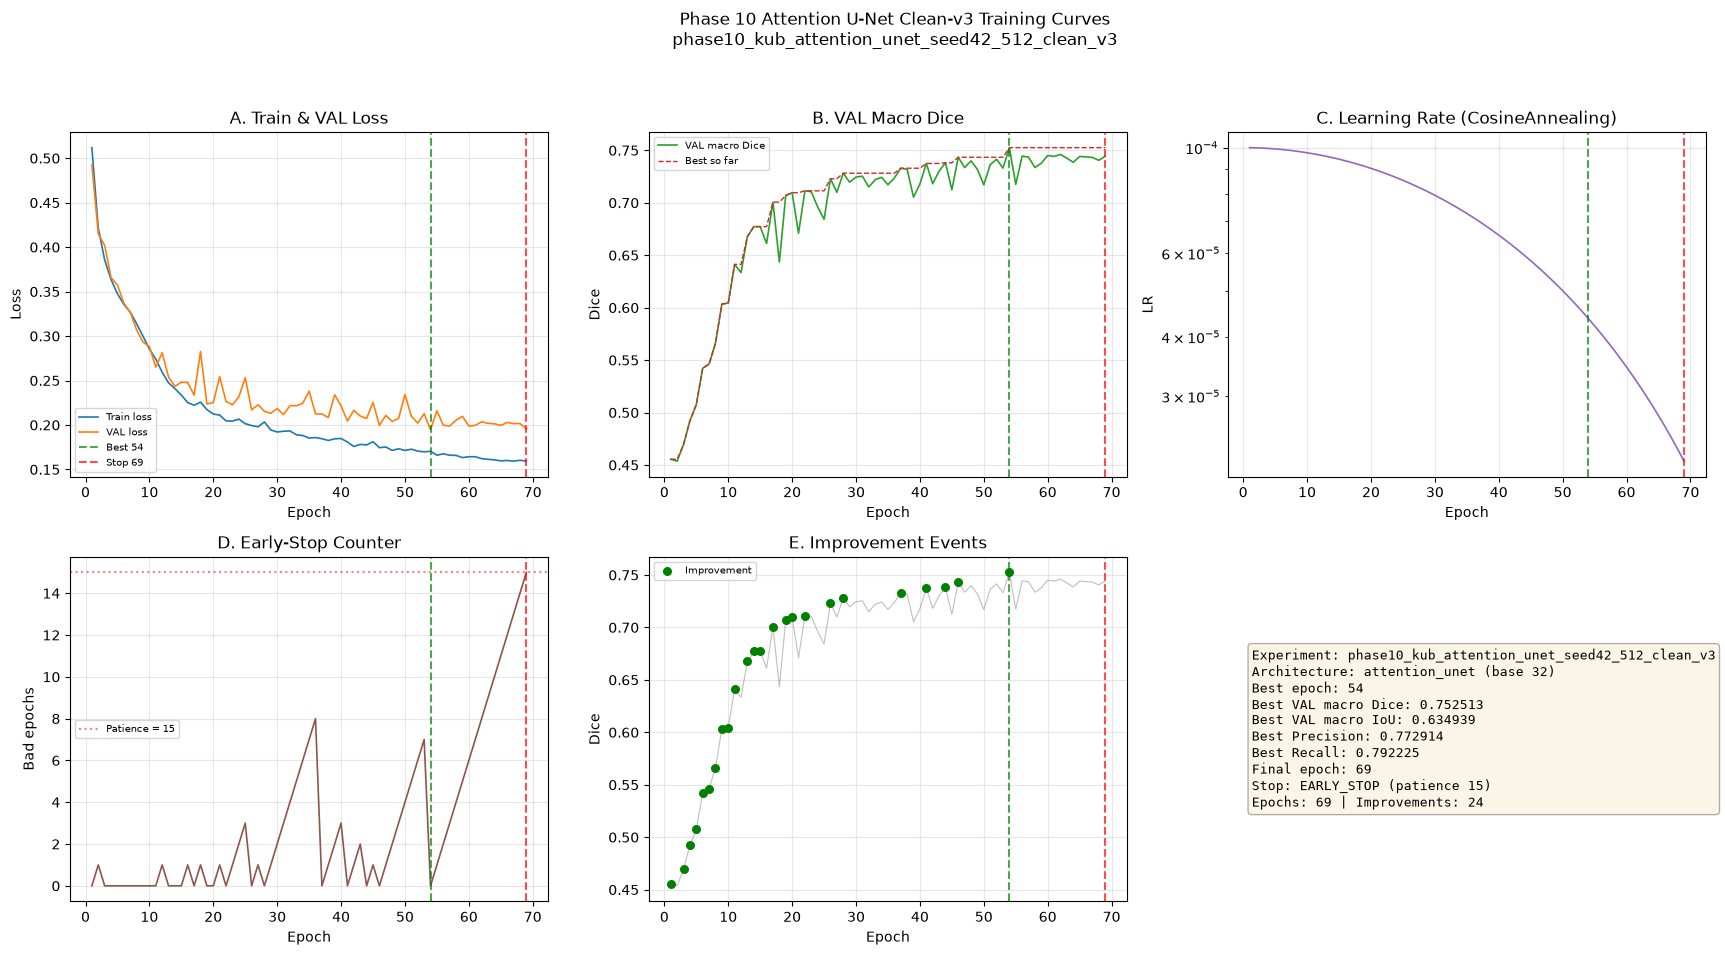

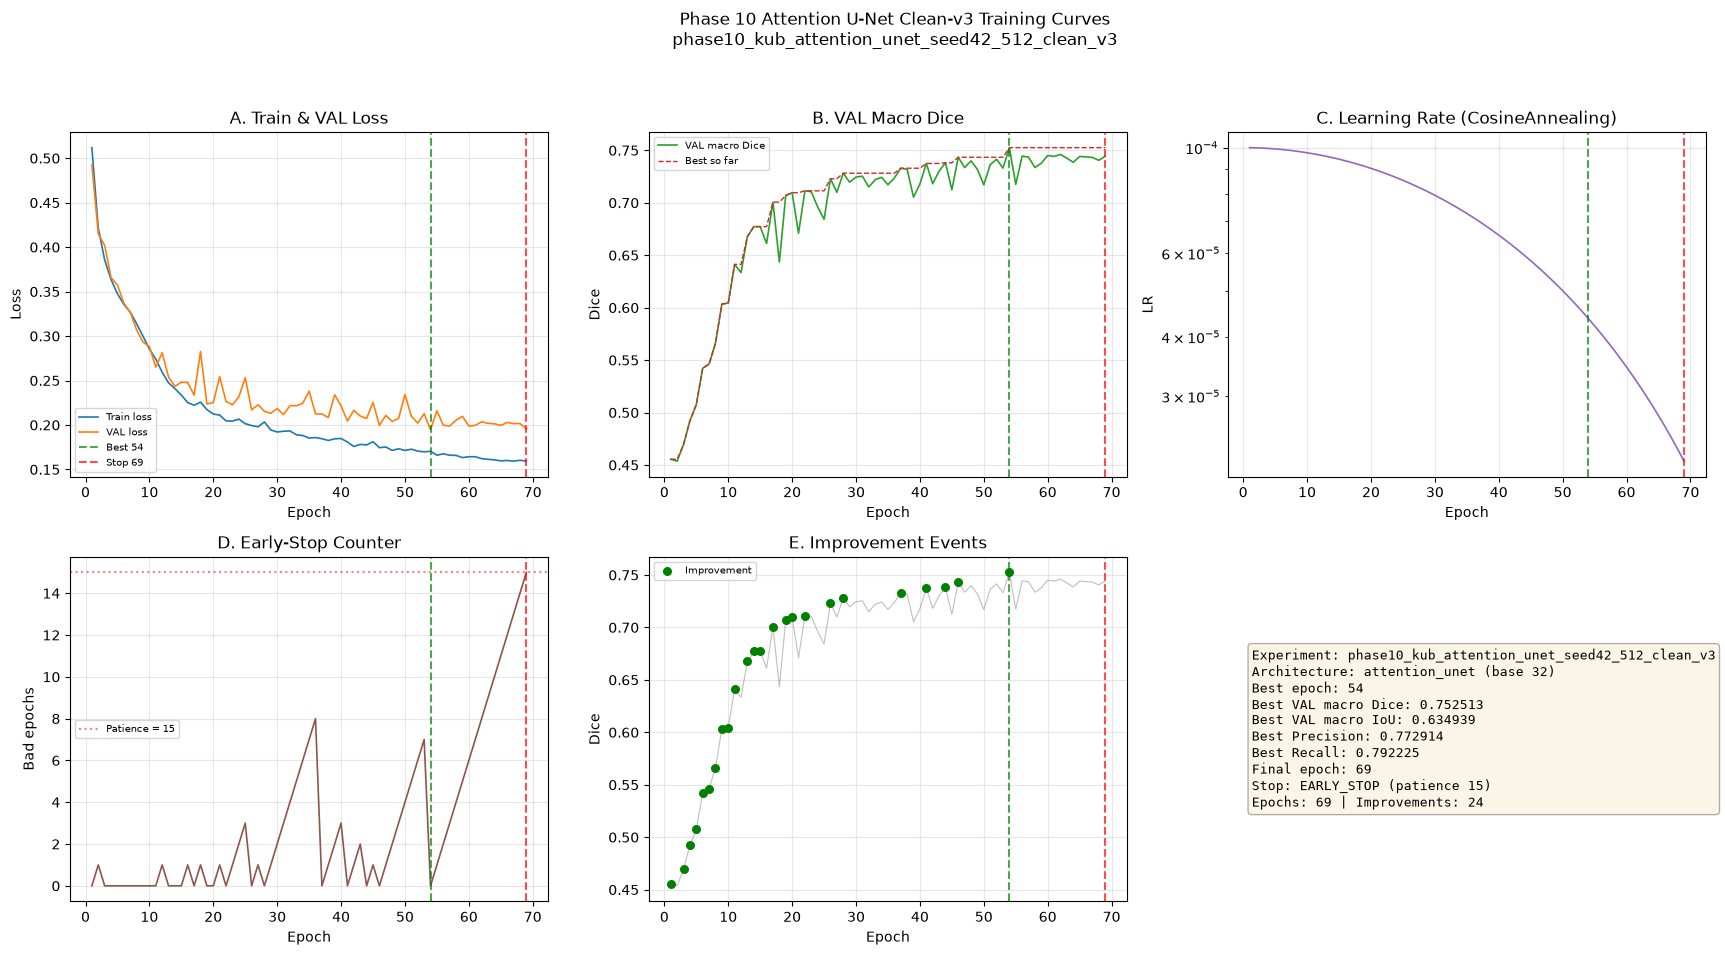

In [13]:
fig = rv.plot_training_curves(df)
curves_path = PROJECT_ROOT / 'reports' / 'figures' / 'phase10_attention_unet_clean_v3_training_curves_review.png'
fig.savefig(curves_path, dpi=150, bbox_inches='tight')
print(f'Curves saved: {curves_path}')
display(fig)


## 14. Attention U-Net VAL Prediction Gallery

Using **best.pt only** (epoch 54) and KUB-only VAL. Threshold fixed at 0.5.
No threshold tuning, no checkpoint switching.

> Gallery metrics are `DETERMINISTIC_GALLERY_SUBSET_ONLY` — descriptive of these
> 16 cases only, NOT the authoritative full-VAL score.


In [14]:
from src.utils.targets import binarize_mask
from src.metrics.segmentation import binary_metrics

model, device = rv.load_best_model_for_inference(device='cuda')
print(f'Model loaded on {device}')
print(f'Model class: {model.__class__.__name__}')
print(f'Parameters : {sum(p.numel() for p in model.parameters()):,}')
print()

# Pre-check
print('=== PRE-CHECK GALLERY SAMPLES ===')
for _, row in gallery_df.iterrows():
    ie = Path(row['image_path']).exists()
    me = Path(row['mask_path']).exists()
    print(f"  {row['gallery_index']:2d} {row['sample_id'][:28]:28s} {'OK' if (ie and me) else 'MISSING'}")


Model loaded on cuda:0
Model class: AttentionUNet
Parameters : 7,850,709

=== PRE-CHECK GALLERY SAMPLES ===
   1 00849cbfea1e926cc0bf0443c9a5 OK
   2 0144956d1749caca131daae62fb5 OK
   3 033668e32b8f9d46165c01d8b9e1 OK
   4 0785b56594049121d6281aa40e47 OK
   5 08d0d5ec1c23988253c6bbd51990 OK
   6 1f7039f2079e8d2e6cb4cac6daa0 OK
   7 416e6f7d9e35c6bf4bde51e191a7 OK
   8 7740904a921b977a9885955d8d58 OK
   9 9057aec09b055e6542208d6f7bf5 OK
  10 b0473630de9211114c94c7dc0363 OK
  11 b5807d0c333c88ffc8b93d118f40 OK
  12 c601e447d2efb705941e8b1ec6c1 OK
  13 d5b2162ad4c439d90f5483fe46d1 OK
  14 ec7d4690db3c071ecd012b3594d7 OK
  15 f1afd69d82aff6da8bc39cdcd5f9 OK
  16 f62138e1d57921c98a7fa5cb5373 OK


Gallery saved: D:\Softfors\jup\reports\figures\phase10_attention_unet_clean_v3_val_gallery.png


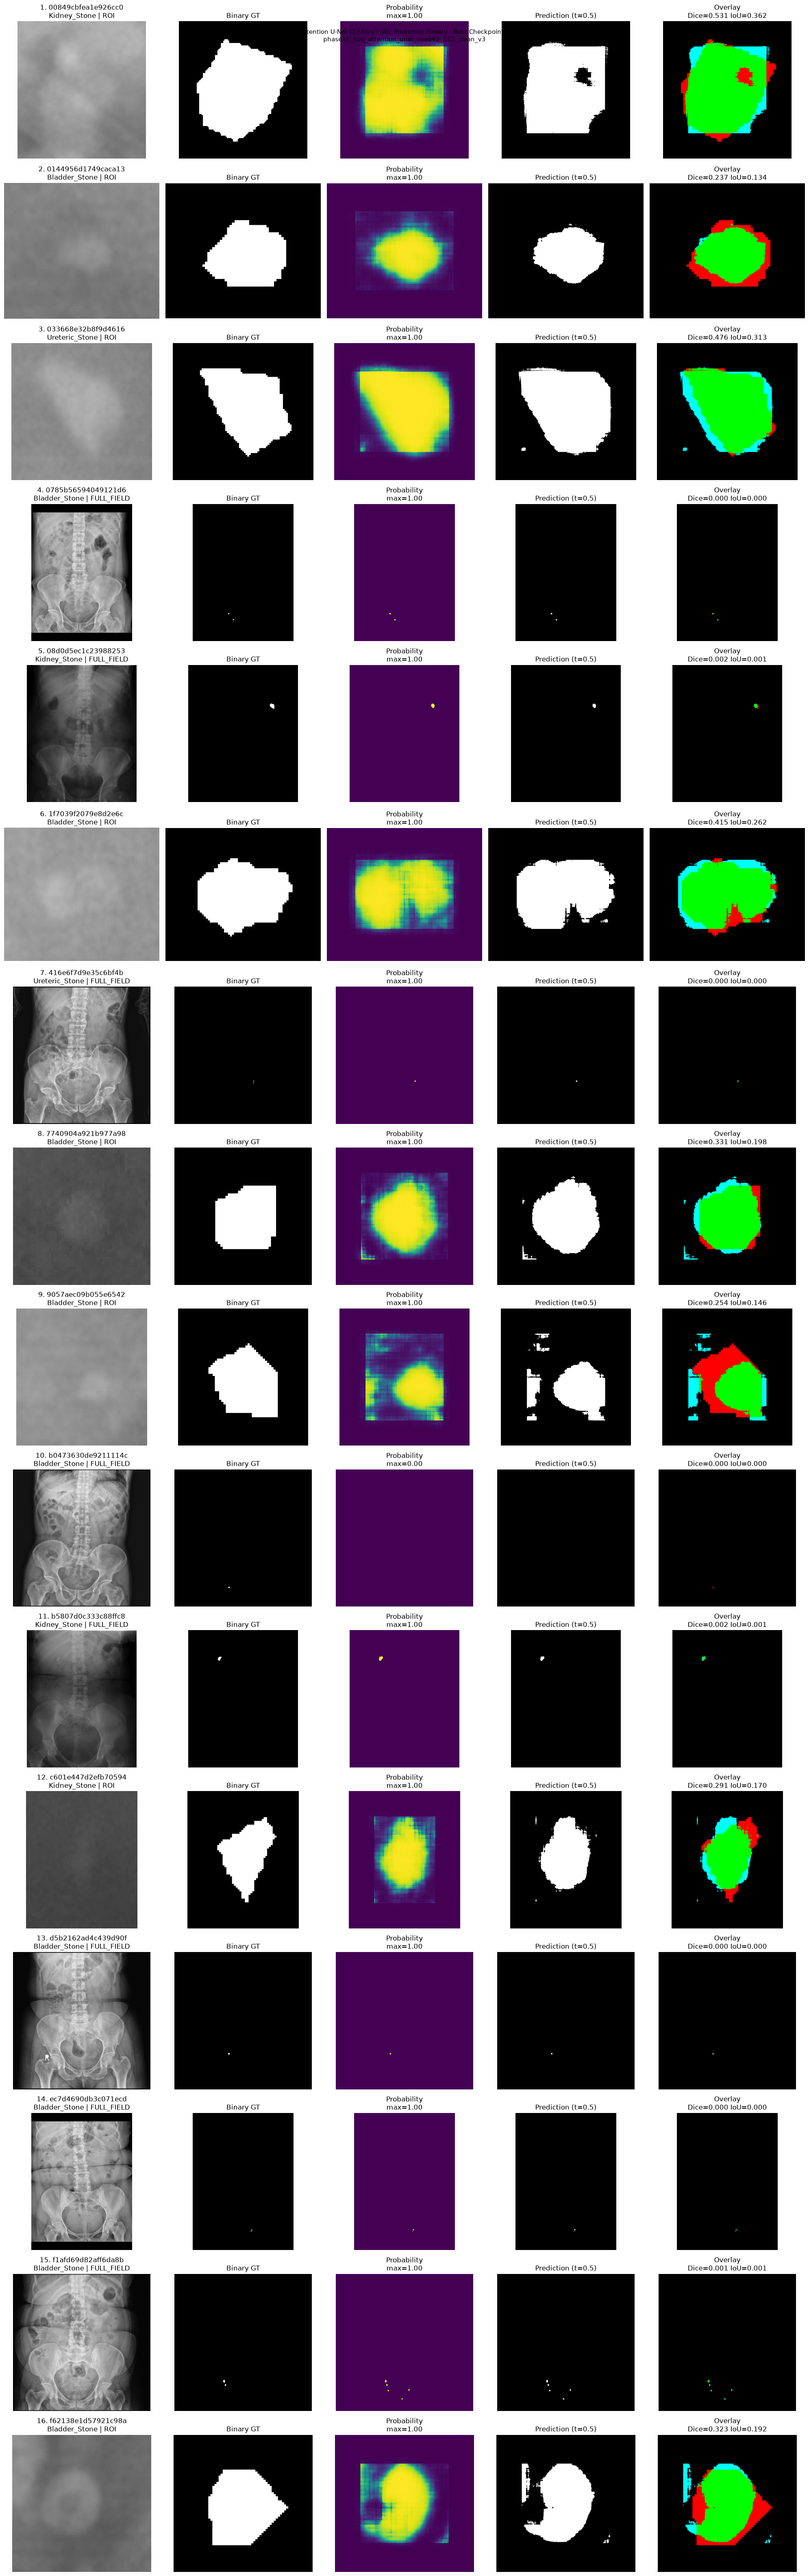

Gallery metrics saved: D:\Softfors\jup\reports\tables\phase10_attention_unet_clean_v3_val_gallery_metrics.csv

=== DETERMINISTIC_GALLERY_SUBSET_ONLY ===
Gallery subset mean Dice: 0.179026
Gallery subset mean IoU : 0.111263

Authoritative full-KUB-VAL metrics (280 cases, best checkpoint):
  Dice     : 0.7525129853960107
  IoU      : 0.6349387691368995
  Precision: 0.7729140812402236
  Recall   : 0.7922248481868364

Gallery means do NOT replace the authoritative metrics above.


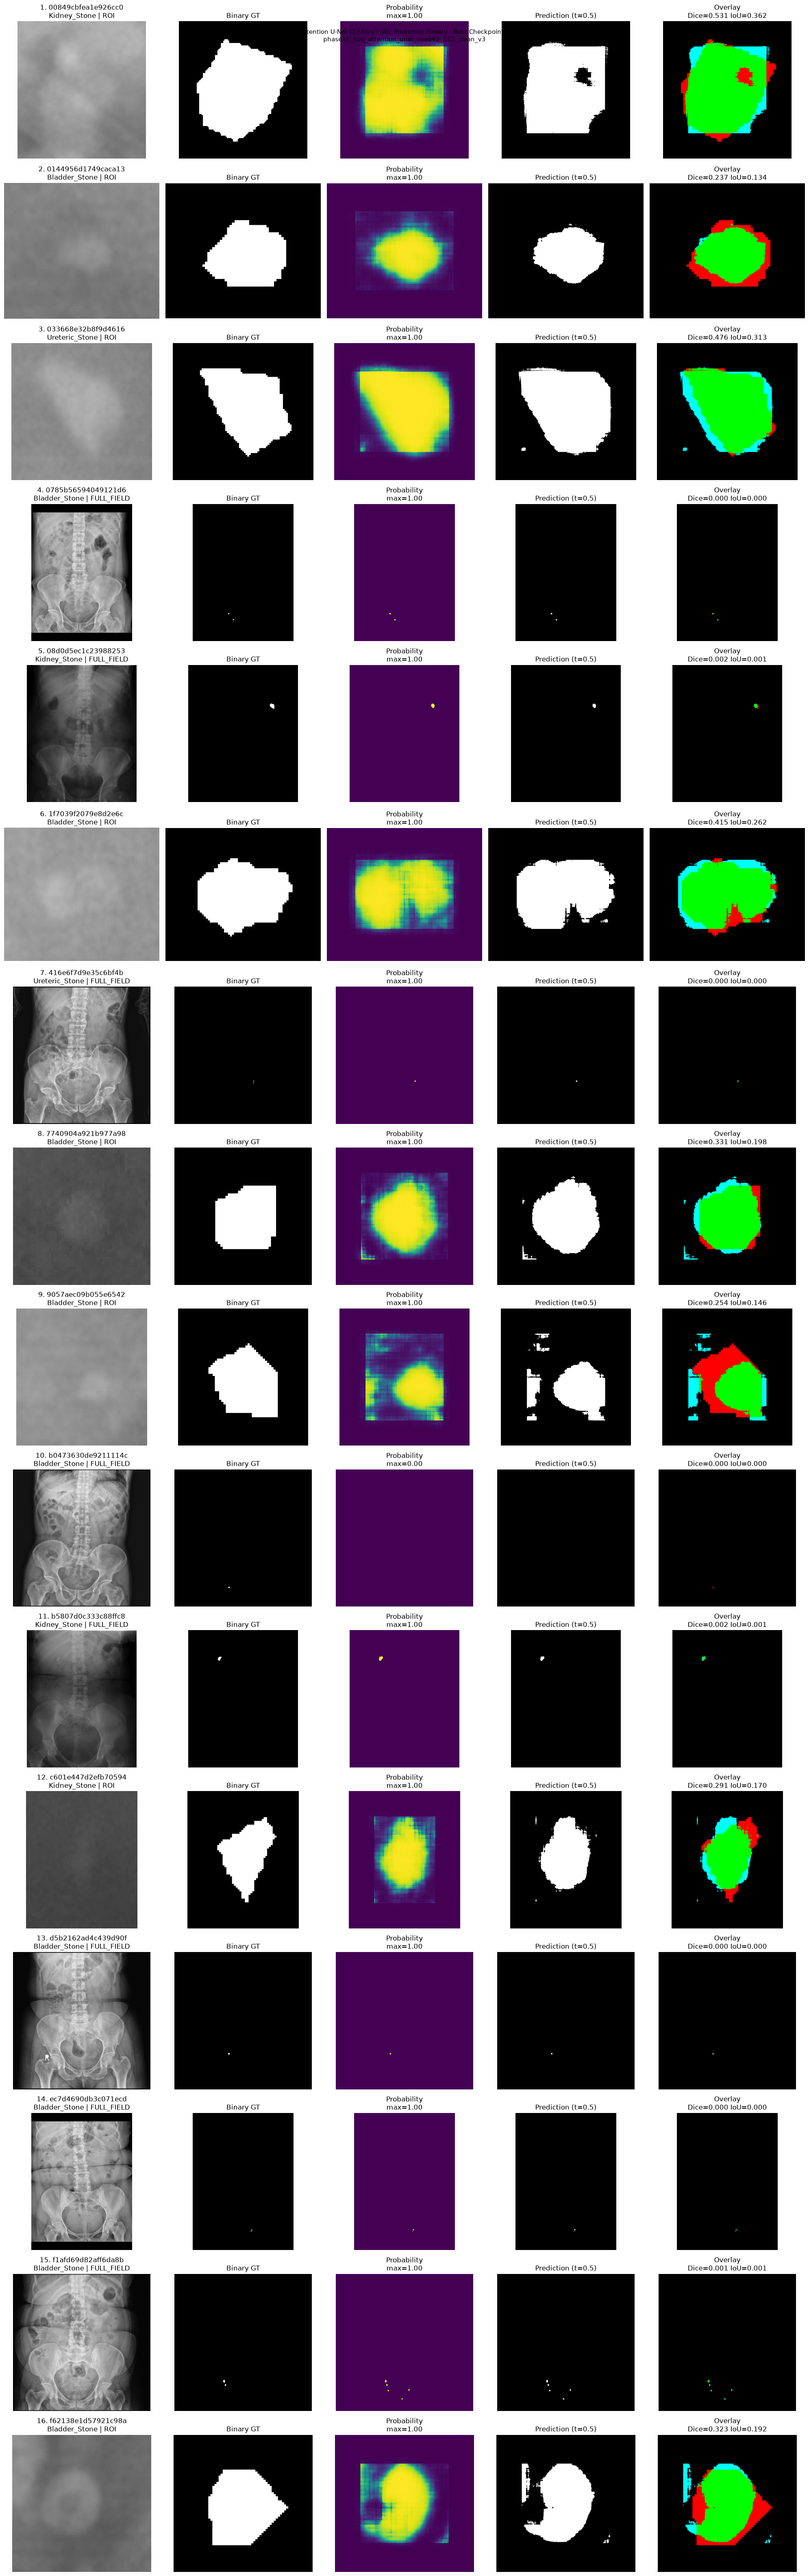

In [15]:
# Generate gallery figure
n_cases = len(gallery_df)
fig, axes = plt.subplots(n_cases, 5, figsize=(20, 4 * n_cases))
fig.suptitle(f'Phase 10 Attention U-Net CLEAN-v3 VAL Prediction Gallery - Best Checkpoint (epoch 54)\n{rv.EXPERIMENT_ID}', fontsize=11)
THRESHOLD = 0.5
gallery_records = []

for idx, (_, row) in enumerate(gallery_df.iterrows()):
    sample_id = row['sample_id']
    img_path = Path(row['image_path'])
    mask_path = Path(row['mask_path'])

    if not img_path.exists() or not mask_path.exists():
        for ax in axes[idx]:
            ax.axis('off'); ax.set_title('MISSING')
        continue

    mask_raw = np.array(Image.open(mask_path).convert('L'))
    gt_mask = binarize_mask(mask_raw).astype(np.uint8)

    prob, (new_w, new_h), (pad_l, pad_t) = rv.predict_on_val_sample(model, device, img_path, target_size=512)
    gt_resized = np.array(Image.fromarray(gt_mask).resize((new_w, new_h), Image.NEAREST))
    pred_mask = (prob >= THRESHOLD).astype(np.uint8)

    d = binary_metrics(torch.from_numpy(gt_resized).float().unsqueeze(0),
                       torch.from_numpy(pred_mask).float().unsqueeze(0), threshold=0.5)
    dice, iou = float(d['dice']), float(d['iou'])

    img_orig = Image.open(img_path).convert('L')
    native = img_orig.size
    img_arr = np.array(img_orig)

    overlay = np.zeros((*pred_mask.shape, 3), dtype=np.uint8)
    overlay[..., 0] = gt_resized * 255
    overlay[..., 1] = pred_mask * 255
    both = gt_resized & pred_mask
    overlay[..., 0] = np.where(both, 0, overlay[..., 0])
    overlay[..., 1] = np.where(both, 255, overlay[..., 1])
    overlay[..., 2] = np.where((gt_resized == 0) & (pred_mask == 1), 255, 0)

    axes_list = axes[idx]
    axes_list[0].imshow(img_arr, cmap='gray', vmin=0, vmax=255)
    axes_list[0].set_title(f'{idx+1}. {sample_id[:18]}\n{row["category"]} | {row["acquisition_type"]}')
    axes_list[0].axis('off')
    axes_list[1].imshow(gt_resized, cmap='gray', vmin=0, vmax=1)
    axes_list[1].set_title('Binary GT'); axes_list[1].axis('off')
    axes_list[2].imshow(prob, cmap='viridis', vmin=0, vmax=1)
    axes_list[2].set_title(f'Probability\nmax={prob.max():.2f}'); axes_list[2].axis('off')
    axes_list[3].imshow(pred_mask, cmap='gray', vmin=0, vmax=1)
    axes_list[3].set_title(f'Prediction (t={THRESHOLD})'); axes_list[3].axis('off')
    axes_list[4].imshow(overlay)
    axes_list[4].set_title(f'Overlay\nDice={dice:.3f} IoU={iou:.3f}'); axes_list[4].axis('off')

    gallery_records.append({
        'gallery_index': idx + 1,
        'sample_id': sample_id,
        'patient_id': row['patient_id'],
        'category': row['category'],
        'acquisition_type': row['acquisition_type'],
        'native_width': native[0],
        'native_height': native[1],
        'pred_width': new_w,
        'pred_height': new_h,
        'dice': dice,
        'iou': iou,
    })

plt.tight_layout()
gal_fig = PROJECT_ROOT / 'reports' / 'figures' / 'phase10_attention_unet_clean_v3_val_gallery.png'
gal_fig.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(gal_fig, dpi=150, bbox_inches='tight')
print(f'Gallery saved: {gal_fig}')
display(fig)

metrics_df = pd.DataFrame(gallery_records)
if len(metrics_df) > 0:
    mpath = PROJECT_ROOT / 'reports' / 'tables' / 'phase10_attention_unet_clean_v3_val_gallery_metrics.csv'
    metrics_df.to_csv(mpath, index=False)
    print(f'Gallery metrics saved: {mpath}')
    print()
    print('=== DETERMINISTIC_GALLERY_SUBSET_ONLY ===')
    print(f'Gallery subset mean Dice: {metrics_df["dice"].mean():.6f}')
    print(f'Gallery subset mean IoU : {metrics_df["iou"].mean():.6f}')
    print()
    print('Authoritative full-KUB-VAL metrics (280 cases, best checkpoint):')
    b = df.loc[df['val_dice'].idxmax()]
    print(f'  Dice     : {b["val_dice"]:.16f}')
    print(f'  IoU      : {b["val_iou"]:.16f}')
    print(f'  Precision: {b["val_precision"]:.16f}')
    print(f'  Recall   : {b["val_recall"]:.16f}')
    print()
    print('Gallery means do NOT replace the authoritative metrics above.')


## 15. Aggregate VAL Metrics (Authoritative)

From the full 280-case KUB VAL at the best checkpoint (epoch 54).


In [16]:
b = df.loc[df['val_dice'].idxmax()]
summary = pd.DataFrame([{
    'experiment_id': rv.EXPERIMENT_ID,
    'architecture': 'attention_unet',
    'manifest_version': 'phase4_v3',
    'taxonomy_id': 'kub_size_clean_v3_v1',
    'best_epoch': int(b['epoch']),
    'best_val_macro_dice': float(b['val_dice']),
    'val_macro_iou': float(b['val_iou']),
    'val_precision': float(b['val_precision']),
    'val_recall': float(b['val_recall']),
    'final_epoch': int(df['epoch'].iloc[-1]),
    'stop_reason': 'EARLY_STOP',
    'early_stop_bad_epochs': int(df['bad_epochs'].iloc[-1]),
    'config_sha': rv.EXPECTED_CONFIG_SHA,
    'history_sha': rv.EXPECTED_HISTORY_SHA,
    'best_checkpoint_sha': rv.EXPECTED_BEST_SHA,
    'latest_checkpoint_sha': rv.EXPECTED_LATEST_SHA,
}])
sp = PROJECT_ROOT / 'reports' / 'tables' / 'phase10_attention_unet_clean_v3_best_val_summary.csv'
summary.to_csv(sp, index=False)
print(f'Best VAL summary saved: {sp}')
print(summary.T.to_string())


Best VAL summary saved: D:\Softfors\jup\reports\tables\phase10_attention_unet_clean_v3_best_val_summary.csv
                                                                                      0
experiment_id                            phase10_kub_attention_unet_seed42_512_clean_v3
architecture                                                             attention_unet
manifest_version                                                              phase4_v3
taxonomy_id                                                        kub_size_clean_v3_v1
best_epoch                                                                           54
best_val_macro_dice                                                            0.752513
val_macro_iou                                                                  0.634939
val_precision                                                                  0.772914
val_recall                                                                     0.792225
final_epoch 

## 16. Limitations

1. **VAL-only evidence** — no TEST metrics. TEST remains locked.
2. **Single architecture** — reviews Attention U-Net only.
3. **No cross-model comparison** — UNet++ and DeepLabV3+ have NOT been rerun, so no
   ranking, winner, or statistical test is possible or claimed.
4. **Gallery is descriptive** — 16-case means are `DETERMINISTIC_GALLERY_SUBSET_ONLY`
   and do not represent full-VAL performance.
5. **Historical separation** — clean-v3 and historical v2 use different TRAIN/VAL
   populations; direct numeric comparison is not a controlled experiment.
6. **No failure analysis** — detailed error-mode analysis is deferred.


## 17. Historical-v2 Separation

| Property | HISTORICAL_v2 | CLEAN_v3 (this run) |
|----------|---------------|---------------------|
| Experiment | `phase10_kub_attention_unet_seed42_512` | `phase10_kub_attention_unet_seed42_512_clean_v3` |
| Manifest | `phase4_v2` | `phase4_v3` |
| Taxonomy | None | `kub_size_clean_v3_v1` |
| Best epoch | 77 | 54 |
| Final epoch | 92 | 69 |
| Best VAL macro Dice | 0.7530131340026855 | 0.7525129853960107 |

The small difference (-0.0005) is within noise and reflects different TRAIN/VAL
membership. It is **not** attributed solely to leakage remediation.


## 18. Phase-10 Status

| Item | Status |
|------|--------|
| Attention U-Net clean-v3 training | **COMPLETE** |
| Attention U-Net reviewer package (this notebook) | **COMPLETE** |
| UNet++ clean-v3 training | **NOT STARTED** |
| DeepLabV3+ clean-v3 training | **NOT STARTED** |
| Final cross-model comparison | **NOT STARTED** |

**No winner is declared.** Phase 10 cannot be concluded until UNet++ and DeepLabV3+
are rerun and reviewed.


## 19. Artifact Hashes


In [17]:
summary_all = rv.full_integrity_summary()
print('=== FULL INTEGRITY SUMMARY ===')
print(json.dumps({
    k: v for k, v in summary_all.items()
    if k not in ('history_integrity', 'artifact_shas', 'best_checkpoint_consistency', 'latest_checkpoint_consistency')
}, indent=2, default=str))
print()
print('Overall pass:', summary_all['overall_pass'])
assert summary_all['overall_pass'], 'Overall integrity FAILED'

# Registry
import hashlib
def _sha(p): return rv.sha256_file(Path(p))
reg = pd.DataFrame([
    {'artifact': 'config', 'path': str(rv.CONFIG_PATH.relative_to(PROJECT_ROOT)), 'sha256': _sha(rv.CONFIG_PATH)},
    {'artifact': 'history', 'path': str(rv.HISTORY_PATH.relative_to(PROJECT_ROOT)), 'sha256': _sha(rv.HISTORY_PATH)},
    {'artifact': 'best_checkpoint', 'path': str(rv.BEST_PT.relative_to(PROJECT_ROOT)), 'sha256': _sha(rv.BEST_PT)},
    {'artifact': 'latest_checkpoint', 'path': str(rv.LATEST_PT.relative_to(PROJECT_ROOT)), 'sha256': _sha(rv.LATEST_PT)},
    {'artifact': 'taxonomy', 'path': str(rv.TAXONOMY_ARTIFACT.relative_to(PROJECT_ROOT)), 'sha256': _sha(rv.TAXONOMY_ARTIFACT)},
    {'artifact': 'training_runner', 'path': 'notebooks/phasewise/phase_10_clean_v3_comparison/code/train_phase10_attention_unet_clean_v3.py', 'sha256': _sha(rv.TRAINING_RUNNER)},
    {'artifact': 'review_support_code', 'path': 'notebooks/phasewise/phase_10_baseline_comparison/code/phase10_attention_unet_review.py', 'sha256': _sha(PROJECT_ROOT/'notebooks'/'phasewise'/'phase_10_baseline_comparison'/'code'/'phase10_attention_unet_review.py')},
    {'artifact': 'gallery_selection', 'path': 'reports/tables/phase10_attention_unet_clean_v3_val_gallery_selection.csv', 'sha256': _sha(PROJECT_ROOT/'reports'/'tables'/'phase10_attention_unet_clean_v3_val_gallery_selection.csv')},
    {'artifact': 'gallery_metrics', 'path': 'reports/tables/phase10_attention_unet_clean_v3_val_gallery_metrics.csv', 'sha256': _sha(PROJECT_ROOT/'reports'/'tables'/'phase10_attention_unet_clean_v3_val_gallery_metrics.csv')},
    {'artifact': 'best_val_summary', 'path': 'reports/tables/phase10_attention_unet_clean_v3_best_val_summary.csv', 'sha256': _sha(PROJECT_ROOT/'reports'/'tables'/'phase10_attention_unet_clean_v3_best_val_summary.csv')},
])
rp = PROJECT_ROOT / 'reports' / 'tables' / 'phase10_attention_unet_clean_v3_artifact_registry.csv'
reg.to_csv(rp, index=False)
print(f'\nArtifact registry saved: {rp}')
print(reg[['artifact','sha256']].to_string(index=False))


=== FULL INTEGRITY SUMMARY ===
{
  "experiment_id": "phase10_kub_attention_unet_seed42_512_clean_v3",
  "architecture": "attention_unet",
  "manifest_version": "phase4_v3",
  "taxonomy_id": "kub_size_clean_v3_v1",
  "overall_pass": true
}

Overall pass: True

Artifact registry saved: D:\Softfors\jup\reports\tables\phase10_attention_unet_clean_v3_artifact_registry.csv
           artifact                                                           sha256
             config 70e08ad5b89461db0bb9cbb8e75da8bbc9ef357af36e5d70a3c4653818260c02
            history ee5073f0bea745280ae7d9a8f651cc4cae72a18d408750623d838f7cd8d24e58
    best_checkpoint a49b19d66e43b57ed082ea6efc0ac10bccf444277abd3540dc68612bf30b88b3
  latest_checkpoint 74a7e612ac9d6a2fcc05c2b25d007f156959d69b3507f198562c07ff4926cd20
           taxonomy 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6
    training_runner 1e215dbf70faf7efc62c725fb8a9c5988362e2e5f4f143022e97545347f1dbfc
review_support_code bc0e96283087443

## 20. Final Boundary Assertions


In [18]:
print('=== REVIEWER NOTEBOOK BOUNDARY ===')
print('Optimizer step calls        : 0  (by construction)')
print('Training epochs executed    : 0  (by construction)')
print('Checkpoint writes           : 0  (by construction)')
print('best.pt modified            : NO')
print('latest.pt modified          : NO')
print('history.csv modified        : NO')
print('config modified             : NO')
print('TEST image reads            : 0')
print('TEST mask reads             : 0')
print('TEST metrics computed       : 0')
print('TEST visualizations         : 0')
print('Cross-model comparison      : NOT PERFORMED')
print('UNet++ started              : NO')
print('DeepLabV3+ started          : NO')
print('Winner declared             : NO')
print()
print('REVIEWER BOUNDARY - PASS')


=== REVIEWER NOTEBOOK BOUNDARY ===
Optimizer step calls        : 0  (by construction)
Training epochs executed    : 0  (by construction)
Checkpoint writes           : 0  (by construction)
best.pt modified            : NO
latest.pt modified          : NO
history.csv modified        : NO
config modified             : NO
TEST image reads            : 0
TEST mask reads             : 0
TEST metrics computed       : 0
TEST visualizations         : 0
Cross-model comparison      : NOT PERFORMED
UNet++ started              : NO
DeepLabV3+ started          : NO
Winner declared             : NO

REVIEWER BOUNDARY - PASS
